# Fine-Tuning and Transfer Learning with an Image Classification Model
# ------------ Author: Ram Mareddy ------------

**Introduction**
 
In this exercise, fine-tuning and transfer learning are performed in an image classification model. The backbone (i.e. base model for this exercise) is MobileNetV3. This has been trained on the large ImageNet dataset. MobileNet architecture lends itself to the resource constrained edge devices like mobile phones. Since ImageNet has 1000 classes (types/categories) of images, this image classification model outputs one of 1000 classes as a prediction.

**Transfer Learning**

Transfer Learning implies transferring the learning the the backbone model has obtained to a new (but related field) problem. Our new problem is classifying the hand-written digits (0 through 9). The learning that's in the parameters (weights and biases) of the backbone - e.g. recognizing edges, shapes, etc. of the image - is useful in recognizing the hand-written digits (which are also images). Training on top of these existing parameters (not initializing them with new random values) retains the original learning in training this new model. This is the essense of transfer learning.

**Fine-Tuning**

While transfer learning is the overall umbrella, fine-tuning is changing/adding specific training to a further area. So, in the MobileNetV3 backbone model, say you kept all the parameters (weights/biases) unchanged (by using requires_grad=False) except for the classification layer (where a new Linear layer that has 10 out features for 10 digits replaces of the original 1000 out features). Here, you applied transfer learning to all the features layers and fine-tuning to the classification layer.

**Scenarios/Options**

In this exercise, multiple fine-tuning scenarios/options are considered: 

1. just train a new classification layer and keep everything else same
2. train a new classification layer and a few features layers on top of their original parameters
3. train the entire model, but start the training on top of the original parameters

So, all these three scenarios are trainsfer learning and fine-tuning. The new model created to recognize the hand-written digits is not being trained from scratch but retains the learning done by MobileNetV3 with its training on ImageNet dataset.

**Flow of a Fine-Tuning Project**

*Understanding the Backbone*: Backbone is the base model used in fine-tuning. Here MobileNetV3 is used as the backbone, which is a pretrained model on TorchVision. Sections II and III look at the models from TorchVision and specifically the architecture of MobileNetV3, including adjusting the model architecture to suit fine-tuning needs.

*Fine-Tuning Data*: Then you need to fine-tuning data to adjust the backbone (the pretrained model). Here, MNIST digits dataset is used to convert the pretrained image classifier into digits classifier. Section IV discusses the fine-tuning scenario and options and the hand-written digits dataset.

*Data Preparation*: Now the data has been identified, it needs to be prepared for training (fine-tuning). Section V discusses splitting traning dataset into training and validation datasets. Once train, validation, and test datasets are made, appropriate transformations are applied to each dataset. And dataloaders are made from these dataset with appropriate batch size.

*Training Preparation*: 

*Finetuning* Classes*:

*Fine-tuning Scenarios*:

*Conclusion*


## Table of Contents

#### [I. Imports](#i-imports)

- [1. Imports Discussion](#1-imports-discussion)

#### [II. Models from TorchVision](#ii-models-from-torchvision)

- [2. Types of Models Available from TorchVision](#2-types-of-models-available-from-torchvision)
- [3. Inspecting MobileNetV3](#3-inspecting-mobilenetv3)
- [4. Creating MobileNetV3 Model with pre-trained Weights](#4-creating-mobilenetv3-model-with-pre-trained-weights)

#### [III. Model Architecture](#iii-model-architecture)

- [5. Model Architecture of MobileNetV3 ](#5-model-architecture)
- [6. Inverted Residual Block](#6-inverted-residual-block)
- [7. Classifier Block](#7-classifier-block)
- [8. Number of Parameters](#8-number-of-parameters)

#### [IV. Fine-Tuning](#iv-finetuning)

- [9. Fine-Tuning Scenario and options](#9-finetuning-scenario)
- [10. Finetuning data (MNIST Digits Datasets)](#10-information-about-digits-datasets)

#### [V. Data Preparation](#v-data-preparation)

- [11. Split into Traning and Validation Datasets](#11-split-into-traning-and-validation-datasets)
- [12. Transformations for Datasets](#12-transformations-for-datasets)
- [13. Apply Transformations to Datasets](#13-apply-transformations-to-datasets)
- [14. Prepare Dataloaders](#14-prepare-traning-and-validation-dataloaders)

#### [VI. Training Preparation](#vi-training-preparation)

- [15. Setup Device](#15-setup-device)
- [16. Change Layers and Turn off Autograd](#16-turn-off-autograd-at-features-layers)
- [17. Prepare Loss Function and Optimizer](#17-prepare-loss-function-and-optimizer)
- [18. Fine-Tuning Loop](#18-fine-tuning-loop)

#### [VII. Fine-Tuning Classes](#vii-fine-tuning-classes)

- [19. FinetuningWeights](#19-finetuningweights)
- [20. FinetuningDataModule](#20-finetuningdatamodule)
- [21. TransformedDataset](#21-transformeddataset)
- [22. FinetuningModule](#22-finetuningmodule)
- [23. FinetuningTrainer](#23-finetuningtrainer)
- [24. FinetuningTrainer](#24-finetuninganalytics)

#### [VIII. Fine-Tuning Scenarios](#viii-fine-tuning-scenarios)

- [25. Scenario 1: Fine-Tuning Classifier](#25-scenario-1-fine-tuning-classifier)
- [26. Scenario 2: Fine-Tuning Classifier plus a few Layers](#26-scenario-2-fine-tuning-classifier-plus-a-few-layers)
- [27. Scenario 3: Fine-Tuning the Entire Model](#27-scenario-3-fine-tuning-the-entire-model)

#### [IX. Conclusion](#ix-conclusion)

- [28. Compare Approaches](#28-compare-approaches)

# I. Imports <a id="i-imports"></a>

Here are the full list of module/library/class imports used in this exercise. They are arranged in a PyTorch-centric way, as opposed to standard way (where the Python imports come on top). The library imports fall into these sections:

1. Main PyTorch Libraries
2. PyTorch Data Utilities
3. Torchvision: Built-in Datasets and Transforms, Pretrained Models
4. Data, Images
5. Display, Plots
6. Python Modules/Classes
7. Custom Library

These imports are discussed in more detail below.

In [1]:
# Main PyTorch Libraries
import torch
import torch.nn as nn
import torch.optim as optim

# PyTorch Data utilities
from torch.utils.data import Dataset, DataLoader, random_split, Subset

# Torchvision: Built-in Datasets and Transforms, Pretrained Models
import torchvision.datasets as datasets
import torchvision.transforms.v2 as T
import torchvision.models as tv_models

# Images, Images
from PIL import Image
import numpy as np
import pandas as pd

# Display, Plots
from tqdm.auto import tqdm
from IPython.display import display, Markdown
import matplotlib.pyplot as plt

# Python Modules/Classes
import math
import random
import inspect
from collections.abc import Sequence

# Custom Library
from finetuning import (
    FinetuningWeights,
    FinetuningDataModule,
    TransformedDataset,
    FinetuningModule,
    FinetuningTrainer,
    FinetuningAnalytics,
)

## 1. Imports Discussion <a id="1-imports-discussion"></a>

**1.1 Main PyTorch Libraries**

`torch, torch.nn, torch.optim`

These are the primary PyTorch libraries (package/module/submodule/library). Any program training neural networks with PyTorch will include these three libraries.

- `torch`: Contains the core deep learning functionality, like Tensors.
- `torch.nn`: nn stands for neural networks. So, here you will find classes like fully connected layers (Linear), convolutional layers (Conv2d), embedding layers (Embedding, EmbeddingBag), Transformer, MaxPool2d, activation functions (ReLU, Adam), loss functions (MSELoss, CrossEntropyLoss). Model architecture is built from a large set of fully implemented layers and other classes in this module.
- `torch.optim`: Optimization classes like SGD, Adam, etc. are in this module.

**1.2 PyTorch Data Utilities**

`torch.utils.data: Dataset, DataLoader, random_split, Subset`

Good, clean, plentiful of data, of course, is the most important ingradient in training a model. PyTorch provides some highly useful data utilities that are directly integrated into the training loop.

- `Dataset`: Provides one sample (inputs and target) at a time based on the index you pass on (with the `__getitem__` it works as an iterator on the samples). It also implements a `__len__` method that provides the number of samples. Transoforms classes can be used from Dataset to transform each sample for use in PyTorch or to introduce small changes as an augmentation (e.g. convert image array into tensor for use in PyTorch training; rotate/flip, etc. to augment the dataset with new samples). Datasets are made for training, validation, testing (and for prediction, after the model is in production)

- `DataLoader`: Used in the training loop. Obtains a batch of samples from Dataset and feeds them to the model for training (loss, backpropagation, optimization), instead of just one sample at a time. Also introduces learning opportunity for the model by shuffling the samples. Like Datasets, DataLoaders are made fro training, validation, testing (and prediction).

- `random_split`: You might have one huge set of samples which need to be split into training, validation, testing, etc. The random_split() function splits the original into these different subsets. It does not duplicate the data, but saves the indices from the original Dataset into multiple SubSets.

- `Subset`: This is derived class from Dataset made by random_split. It has a list of indices for the current need (e.g. training or validation) and will fetch that sample from the original dataset when asked (while iterating).

**1.3 TorchVision: Built-in Datasets and Transforms, Pretrained Models**

TorchVision is a companion package for PyTorch for training vision models. It has built-in image datasets, various required or optional augmentation transforms, and several pretrained models.

`torchvision: datasets, transforms.v2, models`

- `datasets`: Large number of ready to used image datasets (they can be readily initialized as `torch.utils.data.Dataset` classes). Popular image datasets include: MNIST, CIFAR10/100, ImageNet, etc.

- `transforms.v2`: There are two types of transforms classes: 'required' transforms, for example: converting raw images to Tensors (and related transforms that convert the raw images into something usable with PyTorch) and 'augmentation' transforms, where new slightly changed samples (images) are created with things like rotation, flipping, jitter, etc. Here latest v2 is used (but mostly same as v1).

- `models`: Models with popular architectures are pretrained on large dataset (like ImageNet) and the weights are included with torchvision. Popular vision model implementations include: MobileNet (used here), ResNet, AlexNet, GoogLeNet, etc.


# II. Models from TorchVision <a id="ii-models-from-torchvision"></a>

In addition to several built-in datasets, TorchVision has many pretrained models. These pretrained models include the architecture in a class that is easily instantiable from your own code. They also include fully trained weights - most of the CNN/image classifier models on the large ImageNet dataset.


## 2. Types of models available from TorchVision <a id="2-types-of-models-available-from-torchvision"></a>

TorchVision has about 121 models available as classes along with their pretrained weights. These models fall into these categories:

- Image Classification: this is where all the classification models are: ResNet, MobileNet, AlexNet, etc.; biggest list of models numbering about 80
- Detection: provide coordinates to draw bounding boxes around the detected objects
- Semantic Segmentation: models that produce masks to show the identified objects
- Video: inference for the video classification
- Quantization: models that use INT8 instead of FLOAT32 for numbers, thus reducing the size of the models
- Optical Flow: how pixels/objects are moving between frames, useful in object tracking, autonomous driving, etc.

In [2]:
# Classification of TorchVision Models
model_categories = {
    "All Models": None,
    "Image Classification": tv_models,
    "Object Detection": tv_models.detection,
    "Semantic Segmentation": tv_models.segmentation,
    "Video Classification": tv_models.video,
    "Quantization": tv_models.quantization,
    "Optical Flow": tv_models.optical_flow,
}

model_counts = {}
for title, category in model_categories.items():
    model_count = len(tv_models.list_models(module=category))
    model_counts[title] = model_count

display(Markdown("*Number of Models in TorchVision by Classification*"))
df = pd.DataFrame(
    model_counts.items(), columns=["Classification", "Num Models"]
)
display(df.style.hide(axis="index"))

*Number of Models in TorchVision by Classification*

Classification,Num Models
All Models,121
Image Classification,80
Object Detection,12
Semantic Segmentation,6
Video Classification,9
Quantization,12
Optical Flow,2


Following is the pie-chart for pre-trained models in TorchVision. TorchVision, as the name suggests, speicializes in vision models. And, a large number of them fall under Image Classification section.

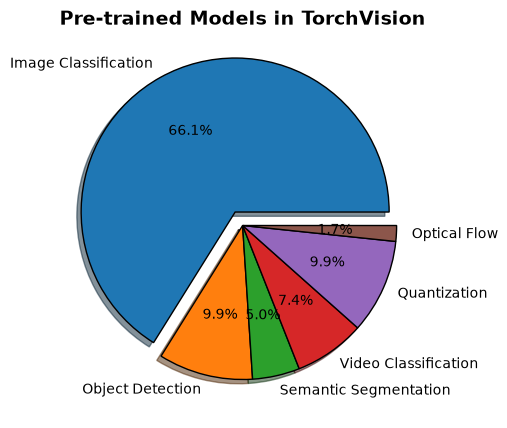

In [ ]:
display(Markdown("*Pie Chart of Models in TorchVision by Classification*"))

# Remove All Models count in preparation of pie chart
df = df[df["Classification"] != "All Models"]

# Pie chart with Model count in different classes
plt.figure(figsize=(5, 5))
plt.title("Pre-trained Models in TorchVision", fontsize=14, fontweight="bold")
plt.pie(
    df["Num Models"],
    labels=df["Classification"],
    explode=[
        0.1 if c == "Image Classification" else 0 for c in df["Classification"]
    ],
    autopct="%1.1f%%",
    wedgeprops={"edgecolor": "black"},
    shadow=True,
)
plt.show()

## 3. Inspecting MobileNetV3 <a id="3-inspecting-mobilenetv3"></a>

This section inspects a few different aspects of the model MobileNetV3 included in TorchVision Models. This inspection is done via `inspect` module in Python. Following are looked at further:

- Source Files
- Classes in MobileNetV3
- Classes derived from nn.Module
- Methods in MobileNetV3 class
- Source

**Source Files**: Each of these models has a source file that includes main class for the model architecture plus other supporting classes.

**Classes in MobileNetV3**: This is a small list of classes for the architecture of the model as well as storing the weights.

In [4]:
source_file = inspect.getfile(tv_models.mobilenetv3)
display(
    Markdown(
        "#### 1. Source File for MobileNetV3 architecture (from the current environment):"
    )
)
print(source_file)

display(Markdown("#### 2. Classes in MobileNetV3"))
classes_in_mv3 = inspect.getmembers(tv_models.mobilenetv3, inspect.isclass)
display(classes_in_mv3)

#### 1. Source File for MobileNetV3 architecture (from the current environment):

/opt/anaconda3/envs/pytorch-learning/lib/python3.13/site-packages/torchvision/models/mobilenetv3.py


#### 2. Classes in MobileNetV3

[('Any', typing.Any),
 ('Conv2dNormActivation', torchvision.ops.misc.Conv2dNormActivation),
 ('ImageClassification', torchvision.transforms._presets.ImageClassification),
 ('InvertedResidual', torchvision.models.mobilenetv3.InvertedResidual),
 ('InvertedResidualConfig',
  torchvision.models.mobilenetv3.InvertedResidualConfig),
 ('MobileNetV3', torchvision.models.mobilenetv3.MobileNetV3),
 ('MobileNet_V3_Large_Weights', <enum 'MobileNet_V3_Large_Weights'>),
 ('MobileNet_V3_Small_Weights', <enum 'MobileNet_V3_Small_Weights'>),
 ('SElayer', torchvision.ops.misc.SqueezeExcitation),
 ('Sequence', collections.abc.Sequence),
 ('Tensor', torch.Tensor),
 ('Weights', torchvision.models._api.Weights),
 ('WeightsEnum', <enum 'WeightsEnum'>),
 ('partial', functools.partial)]

**Classes derived from nn.Module**: These are the main model class as well as layers. MobileNetV3 and InvertedResidual are the main classes from neural network perspective.

In [5]:
display(Markdown("#### 3. Classes derived from nn.Module"))
module_subclasses = [
    (cls, obj) for cls, obj in classes_in_mv3 if issubclass(obj, nn.Module)
]
display(module_subclasses)

mobnetv3_cls = tv_models.mobilenetv3.MobileNetV3

display(Markdown("#### 4. MRO (inheritance) for MobileNetV3 class"))
display(inspect.getmro(mobnetv3_cls))

#### 3. Classes derived from nn.Module

[('Conv2dNormActivation', torchvision.ops.misc.Conv2dNormActivation),
 ('ImageClassification', torchvision.transforms._presets.ImageClassification),
 ('InvertedResidual', torchvision.models.mobilenetv3.InvertedResidual),
 ('MobileNetV3', torchvision.models.mobilenetv3.MobileNetV3),
 ('SElayer', torchvision.ops.misc.SqueezeExcitation)]

#### 4. MRO (inheritance) for MobileNetV3 class

(torchvision.models.mobilenetv3.MobileNetV3,
 torch.nn.modules.module.Module,
 object)

**Methods in MobileNetV3 class**: You will find the required `__init__` and `forward` methods. There is also a `_forward_impl` where the actual forward implementation resides.

**Source**: Source can be printed from inspect.getsourcelines()

In [6]:
display(Markdown("#### 5. Methods in MobileNetV3 class"))
mobnetv3_functions = inspect.getmembers(mobnetv3_cls, inspect.isfunction)
mobnetv3_methods = [
    meth for meth, _ in mobnetv3_functions if meth in mobnetv3_cls.__dict__
]
display(mobnetv3_methods)

display(Markdown("#### 6. A few Source Lines from MobileNetV3 class"))
lines, _ = inspect.getsourcelines(mobnetv3_cls)
display([line.rstrip() for line in lines[0:10]])

#### 5. Methods in MobileNetV3 class

['__init__', '_forward_impl', 'forward']

#### 6. A few Source Lines from MobileNetV3 class

['class MobileNetV3(nn.Module):',
 '    def __init__(',
 '        self,',
 '        inverted_residual_setting: list[InvertedResidualConfig],',
 '        last_channel: int,',
 '        num_classes: int = 1000,',
 '        block: Optional[Callable[..., nn.Module]] = None,',
 '        norm_layer: Optional[Callable[..., nn.Module]] = None,',
 '        dropout: float = 0.2,',
 '        **kwargs: Any,']

## 4. Creating MobileNetV3 Model with pre-trained Weights <a id="4-creating-mobilenetv3-model-with-pre-trained-weights"></a>

To create a MobileNetV3 model of the size you want (small or large), there are some factory functions (or model builder functions) in torchvision.models namespace. These are:

- mobilenet_v3_large
- mobilenet_v3_small

As the names suggest, two different architectures (large vs. small) are used. There are different sets of weights for the larger version, but DEFAULT gives the best version.

In both cases, weights are loaded into the model with load_state_dict() method from nn.Module base class. The state dictionary (of all the trainable parameters and non-trainable buffers) is read from .pth files. These weights files are downloaded from pytorch.org (the download links are in the weight classes). By default, the progress parameter in these model builder functions is set to True, meaning, they show downloading progress bar.

The default large weights for MobileNetV3 model are about 21MB. The file (.pth) is saved by default in the .cache folder (in the torch/hub folder), unless TORCH_HOME environment variable is set to a different folder.

First time when the model weights are downloaded, you will see something like this:

```
Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-5c1a4163.pth" to /Users/rammareddy/.cache/torch/hub/checkpoints/mobilenet_v3_large-5c1a4163.pth
100%|██████████| 21.1M/21.1M [00:00<00:00, 49.5MB/s]
```

In [7]:
def create_pretrained_model() -> nn.Module:
    return tv_models.mobilenet_v3_large(
        weights=tv_models.MobileNet_V3_Large_Weights.DEFAULT, progress=True
    )


mobilenetv3_model = create_pretrained_model()

display(
    f"Current torch.hub directory where .pth files are saved: {torch.hub.get_dir()}"
)

'Current torch.hub directory where .pth files are saved: /Users/rammareddy/.cache/torch/hub'

# III. Model Architecture <a id="iii-model-architecture"></a>


## 5. Architecture of MobileNetV3 <a id="5-architecture-of-mobilenet-v3"></a>

Full listing of the model architecture can be displayed by using print() or display() on the model object. These are some highlights of the MobileNetV3 architecture:

At the highest level, model has three sections:

1. features
2. avgpool
3. classifier

The features section is the largest and contains:

1. Initial Sequential layer
2. Multiple Inverted Residual Blocks (15 in this case - the large version of MobileNetV3)
3. A final Conv2dNormActivation layer

The avgpool section readies the output from features section to be usable by the classifier:

1. One AdaptiveAvgPool2d
2. A flatten layer (not shown, used in forward() method, not defined in `__init__` of the model class)

The classifier section outputs the predictions (1000 classes from these weights, trained on ImageNet):

1. First Linear layer
2. Activation layer: Hardswish (a version of ReLU)
3. Dropout layer with 0.2 probability
4. Final Linear layer with 1000 output features 


In [8]:
display(Markdown("*Architecture of MobileNetV3 Model*"))
# display(mobilenetv3_model)

*Architecture of MobileNetV3 Model*

## 6. Inverted Residual Block <a id="6-inverted-residual-block"></a>

A primary architectural component of MobileNetV3 is a block called Inverted Residual. Each block differs based on the configuration, but following is the typical structure:

1. Each Inverted Residual is Sequential block of 2 or 3 Conv2dNormActivation layers.

2. Each Conv2dNormActivation (as name suggests) is a shortcut for a collection 3 layers that you see repeated often in CNN architectures:

- a Conv2d layer
- a BatchNorm2d layer
- an activation layer (e.g. ReLU)

3. The inputs to outputs in the convolutions layers will start low and go up and then go down (for example):

16 -> 64 -> 24
24 -> 72 -> 24
40 -> 240 -> 80

4. Some InvertedResidual blocks have SqueezeExcitation blocks. This is a collection of 4 layers. First 'squeeze' - with AdaptiveAvgPool2d with an output size of 1. Then conv -> activation -> conv -> activation layers.

In [9]:
display(
    Markdown(
        "*An InvertedResidual block with 3 Conv2dNormActivation blocks and 1 SqueezeExcitation block:*"
    )
)
display(mobilenetv3_model.features[4])

*An InvertedResidual block with 3 Conv2dNormActivation blocks and 1 SqueezeExcitation block:*

InvertedResidual(
  (block): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(24, 72, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (1): BatchNorm2d(72, eps=0.001, momentum=0.01, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
    )
    (1): Conv2dNormActivation(
      (0): Conv2d(72, 72, kernel_size=(5, 5), stride=(2, 2), padding=(2, 2), groups=72, bias=False)
      (1): BatchNorm2d(72, eps=0.001, momentum=0.01, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
    )
    (2): SqueezeExcitation(
      (avgpool): AdaptiveAvgPool2d(output_size=1)
      (fc1): Conv2d(72, 24, kernel_size=(1, 1), stride=(1, 1))
      (fc2): Conv2d(24, 72, kernel_size=(1, 1), stride=(1, 1))
      (activation): ReLU()
      (scale_activation): Hardsigmoid()
    )
    (3): Conv2dNormActivation(
      (0): Conv2d(72, 40, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (1): BatchNorm2d(40, eps=0.001, momentum=0.01, affine=True,

## 7. Classifier Block <a id="7-classifier-block"></a>

This is the final block in MobileNetV3 model ('classifier Head'). It takes a familiar structure of a classifier block:

Fully Connected Layer -> Activation Layer -> Dropout -> Final Fully Connected Layer with outputs for number of classes

Which in this case is (all these layers inside a Sequential so that they execute one after the other):

Sequential(Linear -> Hardswish -> Dropout -> Linear)

After the flattening of the output from features block, you come to 960 input features for the first linear layer. After an activation layer and a dropout of 0.2 probability, final Linear layer outputs 1000 numbers. These correspond to 1000 classes from the ImageNet image classes.

In [10]:
display(Markdown("*Classifier Head - the final block of MobileNetV3*"))
display(mobilenetv3_model.classifier)

*Classifier Head - the final block of MobileNetV3*

Sequential(
  (0): Linear(in_features=960, out_features=1280, bias=True)
  (1): Hardswish()
  (2): Dropout(p=0.2, inplace=True)
  (3): Linear(in_features=1280, out_features=1000, bias=True)
)

Classifier block has just two Linear layers. These two layers have about 2.5 million parameters, surprisingly. That's because these are 'fully connected' layers.

**8.1 First Linear Layer:**

`(0): Linear(in_features=960, out_features=1280, bias=True)`

This Linear layer has 960 inputs (so, these are: x0, x1, x2 ... x959). So, there will be 960 weights (w0, w1, w2, ... w959) and 1 bias. And there are 1280 outputs from this layer. That means there are 1280 units ('neurons'), each with 960 weights and 1 bias. 

So, total parameters (weights+biases) at this linear layer = (960 + 1) * 1280 = 1,230,080

**8.2 Activation and Dropout Layers:**

```
(1): Hardswish()
(2): Dropout(p=0.2, inplace=True)
```

These layers don't have any parameters. They use a standard predefined algorithm, not weights. Hardswish() is like ReLU(); while ReLU() substitutes all the negative values with 0, Hardswish() substitutes values `x <= -3` with 0. For `-3 < x < 3`, it uses the formula x·(x+3)/6. So, -2 becomes -2(-2+3)/6 = -0.3333, and 1 becomes 1(1+3)/6 = 0.6667. Values `x >= 3` are left unchanged, like ReLU().

Similarly Dropout doesn't use any weights. Each value has 20% probability of getting set to 0 (if p=0.2) and the remaining values are multiplied by 1/(1-p). Here that value is 1/(1-0.2) = 1/0.8 = 1.25. So, each of the unchanged values are multiplied by 1.25. 

**8.3 Second Linear Layer:**

`(3): Linear(in_features=1280, out_features=1000, bias=True)`


## 8. Number of Parameters <a id="8-number-of-parameters"></a>

Total number of parameters are the count of all the weights and biases at all the layers in the model. The MobileNetV3 model has two large sections with parameters:

- features layers 
- classifier layers

Total number of parameters are about 5.5 million for the MobileNetV3 (large) model. Features layers have about 3 million parameters and Classifier layers have about 2.5 million parameters. Features block has large number of layers (the ones with parameters are Conv2d and BatchNorm2d). In the Classifier block, only Linear layers have parameters.



In [11]:
def param_count(model: nn.Module, section: str = "") -> int:
    """Counts parameters for a named layer group.

    Args:
        model: Model object.
        section: Prefix of the named layers. For example, features layers might start
            with the word 'features'; classifier layers might start with 'classifier'.
            Empty string will give total parameter count.

    Returns:
        Number of parameters.
    """
    params = [
        param
        for name, param in model.named_parameters()
        if name.startswith(section)
    ]
    total = 0
    for param in params:
        total += param.numel()
    return total


display(Markdown("*Parameter Count in MobileNetV3 (large)*"))

param_dict = {
    "total params": param_count(mobilenetv3_model),
    "feature params": param_count(mobilenetv3_model, "features"),
    "classifier params": param_count(mobilenetv3_model, "classifier"),
}

df = pd.DataFrame(param_dict.items(), columns=["metric", "value"])
display(df.style.hide(axis="index").format({"value": "{:,}"}))

*Parameter Count in MobileNetV3 (large)*

metric,value
total params,"5,483,032"
feature params,"2,971,952"
classifier params,"2,511,080"


This is the last linear layer. The parameters here are:

(1280 + 1) * 1000 = 1,281,000

**4. Total Parameters at Classifier Layers:**

Linear 1 = 1,230,080
Linear 2 = 1,281,000

Total = 2,511,080

In [12]:
# 2. Parameters in the Classifier Layers

display(Markdown("*Parameters in Classifier Layer:*"))
params = [
    (name, param)
    for name, param in mobilenetv3_model.named_parameters()
    if name.startswith("classifier")
]
for name, param in params:
    print(f"{name}: {param.numel():,}")

*Parameters in Classifier Layer:*

classifier.0.weight: 1,228,800
classifier.0.bias: 1,280
classifier.3.weight: 1,280,000
classifier.3.bias: 1,000


## 16. Change Layers and Turn off Autograd <a id="16-turn-off-autograd-at-features-layers"></a>



In [13]:
def turn_off_features_grad(model: nn.Module):
    for param in model.features.parameters():
        param.requires_grad = False


def turn_off_features_grad_except(last_num_layers: int, model: nn.Module):
    turn_off_features_grad(model)
    for i in range(last_num_layers):
        for param in model.features[-i].parameters():
            param.requires_grad = True

In [14]:
def add_new_final_classifier_layer(
    new_out_features: int, model: nn.Module
) -> None:
    # Classifier Block
    display(Markdown("*Classifier Block:*"))
    display(model.classifier)

    # Final Linear layer of the classifier
    final_layer = model.classifier[-1]
    display(Markdown("*Final Linear layer:*"))
    display(final_layer)

    # Keep the input features coming into this final layer
    in_features = final_layer.in_features

    # Create new final classifier layer
    new_classifier_output_layer = nn.Linear(
        in_features=in_features, out_features=new_out_features, bias=True
    )
    display(Markdown("*New Final Linear layer:*"))
    display(new_classifier_output_layer)

    # Replace final classifier layer
    model.classifier[-1] = new_classifier_output_layer
    display(Markdown("*New Classifier:*"))
    display(model.classifier)

# IV. Fine-Tuning Data <a id="iv-fine-tuning-data"></a>



## 9. Fine-tuning Scenario and Options <a id="9-finetuning-scenario"></a>

The weights downloaded here for MobileNetV3 reflect the training on ImageNet1k, which has exactly 1000 non-overlapping classes of images. Hand-written digits are not part of this dataset. So, if you ask for inference on these images of 0-9 handwritten digits, the model will predict one of the 1000 classes it was trained on. But from that training using 1.2 million images, the model would have learned the edge detection and other low-level filters. If all we want from our new model is to recognize digits from 0 through 9, we can train the model (all layers or selective layers) with a dataset of handwritten digit images and change the classifier output from 1000 to 10.

Remainder of this notebook looks at various ways of achieving this finetuning.

**Options for Fine-tuning**

**EMNIST Dataset**

Here the finetuning is done for digits (0-9) from the EMNIST dataset. This is a dataset available for download from torchvision.datasets. It comes with several splits - and the split that we are interested in is digits.

In [15]:
# Download the raw data files if needed and create training and testing datasets
train_digit_dataset = datasets.EMNIST(
    "./data/EMNIST", split="digits", train=True, download=True
)
test_digit_dataset = datasets.EMNIST(
    "./data/EMNIST", split="digits", train=False, download=True
)

print(type(train_digit_dataset))

<class 'torchvision.datasets.mnist.EMNIST'>


## 10. Fine-tuning Data (MNIST Digits Datasets) <a id="10-information-about-digits-datasets"></a>

**10.1 Dataset Type and MRO**

The dataset used here is from torchvision.datasets.mnist module: EMNIST. As shown in the MRO (Method Resolution Order) for this class, all the torchvision datasets have Dataset as the ultimate base class. On the way, they also have VisionDataset (defined in torchvision) as base class. For some datasets, VisionDataset is the immediate base class; and for some it is one more level deep (for example: EMNIST -> MNIST -> VisionDataset).

Since EMNIST is a Dataset, it implements `__len__` and `__getitem__` methods. From these methods we can get the length (number of samples) and a particular sample via index, i.e. `[idx]`.

**10.2 Number of Samples**

While initializing a dataset, we can set train=True or False to make training dataset or test dataset. In this case there are 240k training samples and 40k test samples. All these are images of hand written digits from 0-9.

**10.33 A sample Image**

When a Dataset is accessed with an `[index]` for a sample, it returns a tuple of (image, label). For these datasets, no transformation has been done by setting `transform` parameter to a set of transforms including changing the image array to a tensor. So, at this point, the dataset still returns an image that can be displayed by display() or imshow() from matplotlib. All the digit images are of size 28x28. Note that torchvision's EMNIST images are stored transposed (rotated and flipped compared to MNIST), so the sample digit below appears mirrored until a transform corrects it.

In [16]:
# 1. Dataset Type and MRO

ds_class = type(train_digit_dataset)
display(Markdown("*Class for datasets:*"))
display(ds_class)

display(Markdown(f"*MRO for {ds_class}:*"))
display(inspect.getmro(ds_class))

# 2. Number of Samples

train_samples = len(train_digit_dataset)
test_samples = len(test_digit_dataset)

display(Markdown("*Number of Samples*:"))
display(
    Markdown(
        f"Samples in Training Dataset: {train_samples:,} <br>\
        Samples in Test Dataset: {test_samples:,}"
    )
)


*Class for datasets:*

torchvision.datasets.mnist.EMNIST

*MRO for <class 'torchvision.datasets.mnist.EMNIST'>:*

(torchvision.datasets.mnist.EMNIST,
 torchvision.datasets.mnist.MNIST,
 torchvision.datasets.vision.VisionDataset,
 torch.utils.data.dataset.Dataset,
 typing.Generic,
 object)

*Number of Samples*:

Samples in Training Dataset: 240,000 <br>        Samples in Test Dataset: 40,000

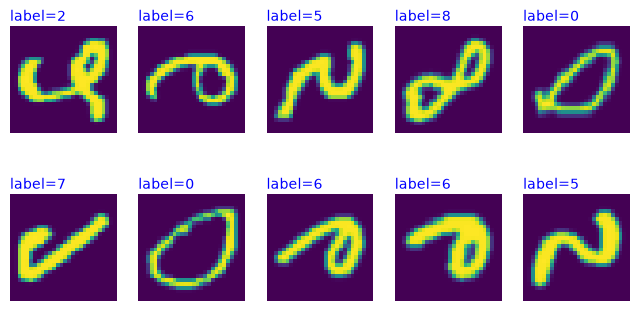

In [17]:
# 3. A sample Images
def show_sample_imgs(ds: Dataset, transformed: bool = False) -> None:
    """Display image grid with label, img, prediction."""
    fig, axes = plt.subplots(nrows=2, ncols=5, figsize=(8, 4))

    max_idx = len(ds) - 1

    idxs = [random.randint(0, max_idx) for i in range(10)]
    samples = [ds[idx] for idx in idxs]
    for idx, ax in enumerate(axes.flatten()):
        img, label = samples[idx]
        if transformed:
            img = img.permute(1, 2, 0).clamp(0, 1)

        ax.axis("off")
        # ax.imshow(img, cmap="gray")
        ax.imshow(img)

        ax.text(
            0,
            1.05,
            f"label={label}",
            color="blue",
            transform=ax.transAxes,
        )

    plt.show()


show_sample_imgs(ds=train_digit_dataset)

## V. Data Preparation <a id="v-data-preparation"></a>



## 11. Split into Traning and Validation Datasets <a id="11-split-into-traning-and-validation-datasets"></a>

We have Training and Testing Datasets downloaded from MNIST Dataset class of torchvision. These sets contain 240k samples for training and 40k samples for testing. There is no separate validation set. I will take 40k from training set and make it validation set. So, following will be the sizes of datasets after the split:

- training: 200k
- validation: 40k
- testing: 40k

The ratios are roughly 70% training, 15% for validation, and 15% for testing (though rounding off the sizes to nearest 10k, makes the actual percentages slightly different).

In [18]:
def split_train_val(
    dataset: Dataset, lengths: tuple[int, int]
) -> tuple[Subset, Subset]:
    """Splits a dataset into just two subsets by using the numbers provided in lengths tuple.

    Args:
        dataset: The Dataset to be split.
        lengths: Number of samples in each dataset (total should equal to the samples in the
        dataset to be split.

    Returns:
        tuple[Subset, Subset]: Two Subset objects (Subset is derived from Dataset)
    """
    train_dataset, val_dataset = random_split(dataset, lengths=lengths)
    return train_dataset, val_dataset

In [19]:
# Split the initial 240k dataset

train_dataset_size = 200000
val_dataset_size = 40000
train_dataset_o, val_dataset_o = split_train_val(
    dataset=train_digit_dataset, lengths=(train_dataset_size, val_dataset_size)
)

# Sizes of datasets after splitting

display(Markdown("*Sizes of traning and validation datasets after splitting*"))
display(
    Markdown(
        f"Training Dataset: {len(train_dataset_o):,} <br> \
                 Validation Dataset: {len(val_dataset_o):,}"
    )
)

*Sizes of traning and validation datasets after splitting*

Training Dataset: 200,000 <br>                  Validation Dataset: 40,000

## 12. Transformations for Datasets <a id="12-transformations-for-datasets"></a>

Current datasets have inputs (images) in the PIL.Image format. For PyTorch training to work a few different kinds of transformations need to be performed on the data:

Documentation for weights:
https://docs.pytorch.org/vision/stable/models/generated/torchvision.models.mobilenet_v3_large.html#torchvision.models.MobileNet_V3_Large_Weights

- The digits in EMNIST dataset are grayscale images. So, these images don't have 3 channels (RGB), but just 1 channel. The MobileNetV3 model has been trained with images of 3 channels. So, we need to introduce 3 channels into these images.
- The digits in EMNIST data set are 28x28. For training, the ImageNet images have been resized to 224x224 in MobileNetV3. We need to resize EMNIST images as well.
- Original dataset is transposed, as you can see from the digit display in a previous cell (this is because of a historical reason in dataset creation). This needs to be fixed.

- Images need to be transformed into tensors. The numbers in PyTorch are tensors (for autograd capability, ability to run on GPUs, etc.).
- For the deep learning algorithms to be effective, these numbers should be normalized. The pixel RGB values range between 0-255. Use the mean and standard deviation values from the ImageNet dataset. Mean and std for normalization are mentioned in the documentation.

- Then we can add more transformations to give small random variations to the images so that model sees more images during training.

In [20]:
# Original size: 28x28
# MobileNetV3 is trained with 224x224.
new_image_size = [224, 224]

# For normalization
imagenet_mean = [0.485, 0.456, 0.406]
imagenet_std = [0.229, 0.224, 0.225]

basic_transformations = [
    T.Grayscale(num_output_channels=3),
    T.Resize(size=new_image_size),
    T.ToImage(),
    T.Lambda(lambda img: img.transpose(-2, -1)),
    T.ToDtype(dtype=torch.float32, scale=True),
    T.Normalize(imagenet_mean, imagenet_std),
]

augmentation_transformations = [
    T.RandomRotation(degrees=5),
    T.RandomAdjustSharpness(sharpness_factor=1.5, p=0.3),
    T.ColorJitter(brightness=0.1, contrast=0.1),
    T.RandomVerticalFlip(p=1.0),
    T.RandomAffine(degrees=5, translate=(0.05, 0.05), scale=(0.95, 1.05)),
]

training_transformations = T.Compose(
    augmentation_transformations + basic_transformations
)

# Call this eval_transformation which can be used for both validation and test.
validation_transformations = T.Compose(basic_transformations)

## 13. Apply Transformations to Datasets <a id="13-apply-transformations-to-datasets"></a>







```
class TransformedDataset(Dataset):
    def __init__(self, dataset: Dataset, transform: T.Transform):
        self.dataset = dataset
        self.transform = transform

    def __getitem__(self, index: int) -> tuple[torch.Tensor, torch.Tensor]:
        img, label = self.dataset[index]
        img_t = self.transform(img)
        return img_t, label

    def __len__(self) -> int:
        return len(self.dataset)
```

In [21]:
train_dataset = TransformedDataset(
    dataset=train_dataset_o, transform=training_transformations
)
val_dataset = TransformedDataset(
    dataset=val_dataset_o, transform=validation_transformations
)


Images after transformation


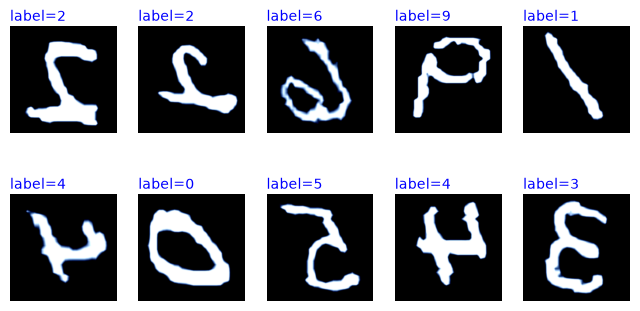

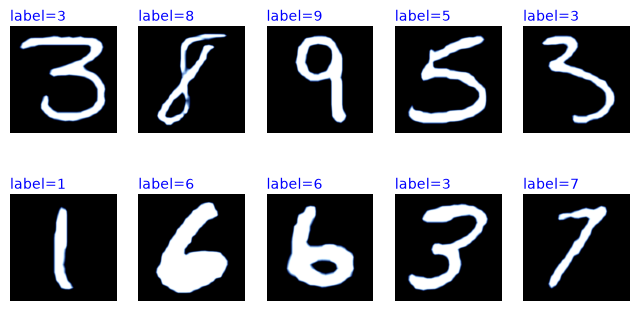

In [22]:
show_sample_imgs(ds=train_dataset, transformed=True)
show_sample_imgs(ds=val_dataset, transformed=True)

## 14. Prepare DataLoaders <a id="14-prepare-traning-and-validation-dataloaders"></a>


In [23]:
batch_size = 256
train_loader = DataLoader(
    dataset=train_dataset,
    batch_size=batch_size,
    shuffle=True,
)
val_loader = DataLoader(
    dataset=val_dataset,
    batch_size=batch_size,
    shuffle=False,
)

# VI. Training Preparation <a id="vi-training-preparation"></a>



## 15. Setup Device <a id="18-setup-device"></a>



In [24]:
def choose_device(seed: int = 42) -> torch.device:
    torch.manual_seed = seed
    device = torch.device("cpu")

    if torch.cuda.is_available():
        device = torch.device("cuda")
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

    elif torch.backends.mps.is_available():
        device = torch.device("mps")
        torch.mps.manual_seed = seed

    display(Markdown(f"Device to be used: {device}"))
    return device


device = choose_device()

Device to be used: mps

## 17. Prepare loss function and optimizer <a id="17-prepare-loss-function-and-optimizer"></a>

In [25]:
def create_loss_optim(model: nn.Module, learning_rate: float):
    loss_function = nn.CrossEntropyLoss()

    # See if adding different learning rates to classifier and backbone helps.
    # Say, 0.001 for classifier and 0.0001 for the backbone,
    # so that the earlier learning/weights are not destroyed.
    optimizer = optim.SGD(
        filter(lambda p: p.requires_grad, model.parameters()), lr=0.001
    )
    return loss_function, optimizer

## 18. Fine-Tuning Loop <a id="18-fine-tuning-loop"></a>


In [26]:
def fine_tuning_loop(
    model: nn.Module,
    loss_function: nn.Module,
    optimizer: optim.Optimizer,
    train_loader: DataLoader,
    val_loader: DataLoader,
    device: torch.device,
    num_epochs: int,
) -> nn.Module:
    model.to(device)
    total_loss = 0
    results = {}
    for epoch in range(num_epochs):
        # Training
        model.train()
        num_training_batches = math.ceil(
            len(train_loader.dataset) / train_loader.batch_size
        )
        for idx, (inputs, labels) in tqdm(
            enumerate(train_loader),
            desc="Training",
            total=num_training_batches,
            unit="epochs",
        ):
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
            preds = model(inputs)

            loss = loss_function(preds, labels)
            loss.backward()
            optimizer.step()

            total_loss += loss.item()
            if idx % 100 == 0:
                print(f"batch = {idx}, loss = {loss.item():.4f}")

        print(f"Completed: batch = {idx}, loss = {loss.item():.4f}")

        # Evaluation
        model.eval()
        correct = 0
        num_checked = 0
        num_eval_batches = math.ceil(
            len(val_loader.dataset) / val_loader.batch_size
        )
        for val_idx, (val_inputs, val_labels) in tqdm(
            enumerate(val_loader),
            desc="Validation",
            total=num_eval_batches,
            unit="epochs",
        ):
            with torch.no_grad():
                val_inputs, val_labels = (
                    val_inputs.to(device),
                    val_labels.to(device),
                )
                preds = model(val_inputs)
                _, pred_classes = preds.max(1)
                correct += (pred_classes == val_labels).sum()

                num_checked += len(val_labels)
                if val_idx % 20 == 0:
                    print(f"Checked = {num_checked:,}, Correct = {correct:,}")

        # Epoch Report
        accuracy = correct / num_checked
        print(f"Total Checked = {num_checked:,}, Total Correct = {correct:,}")
        print(
            f"Epoch: {epoch} Final Loss: {loss:.4f}, Accuracy: {accuracy * 100:.2f}%"
        )
        results[f"epoch{epoch}"] = accuracy

    return model, results

## 19. Predictions



In [27]:
def predict_digit(idx: int, model: nn.Module, dataset: Dataset) -> bool:
    img, label = dataset[idx]
    img_t = validation_transformations(img)
    img_t = img_t.to(device)
    img_t = img_t.unsqueeze(0)

    model = model.to(device)
    model.eval()
    with torch.no_grad():
        pred_t = model(img_t)

    pred_val, pred_index = pred_t.max(1)
    prediction = pred_index.item()
    return label == prediction

In [28]:
test_digit_dataset.transform = validation_transformations
test_loader = DataLoader(
    test_digit_dataset, batch_size=batch_size, shuffle=False
)


def check_test_dataset(
    model: nn.Module,
    test_loader: DataLoader,
    device: torch.device,
) -> None:
    model.eval()
    correct = 0
    num_checked = 0
    num_test_batches = math.ceil(
        len(test_loader.dataset) / test_loader.batch_size
    )
    for test_idx, (test_inputs, test_labels) in tqdm(
        enumerate(test_loader), desc="Testing:", total=num_test_batches
    ):
        with torch.no_grad():
            test_inputs, test_labels = (
                test_inputs.to(device),
                test_labels.to(device),
            )
            preds = model(test_inputs)
            _, pred_classes = preds.max(1)
            correct += (pred_classes == test_labels).sum()

            num_checked += len(test_labels)
            if test_idx % 20 == 0:
                print(f"Checked = {num_checked:,}, Correct = {correct:,}")

    # Final Report
    accuracy = correct / num_checked
    print(f"Total Checked = {num_checked:,}, Total Correct = {correct:,}")
    print(f"Accuracy: {accuracy * 100:.2f}%")


# VII. Fine-Tuning Classes <a id="vii-fine-tuning-classes"></a>


All the discussion above is consolidated below into five classes:

- FinetuningWeights
- FinetuningDataModule
- TransformedDataset
- FinetuningModule
- FinetuningTrainer
- FinetuningAnalytics

These are somewhat modeled on LightningDataModule and LightningModule, which are lot more powerful, but they hide all this implementation. Plus the metrics in this case limited to calculated loss and accuracy (`torchmetrics` library is not used). The training_step method contains the entire training to be executed in one epoch. And the code for fit() method is written in the FinetuningTrainer class.

In a typical LightningModule, you will define the model architecture. You will pass the number of layers of each type to construct a full model architecture. In our case, the model architecture is fully defined and available already (from MobileNetV3); in this case, the parameters are passed to the constructor to enable/disable layers for training.

The FinetuningTrainer class is also limited compared to Trainer class in Lightning - no profiling, etc. There is no separate selection of hardware: it chooses CUDA, if one is available, then looks for MPS (MacBookPro laptop), and then finally to CPU. Needless to say, this code doesn't provide callback functionality.

## 19. FinetuningWeights <a id="19-finetuningweights"></a>

In TorchVision, the weights classes themselves contain some useful information outside the classes, like the transformations used in the original training in using the original data set (in this case ImageNet). This transforms() method holds the mean and std of the original image dataset (ImageNet). One of the base transformation on the new image dataset is to transforms.Normalize(), which normalizes the values in the tensors by using mean and std. Instead of typing these numbers by hand, we can get it from the FinetuningWeights class.

Another important value is the size the images used in the original image set. ImageNet has images of all different sizes, but for training a model, you would need to standardize on an image size. This final image size can be obtained from `crop-size` applied to these images. In order to transfer the learning from the original training, we would need to make our new finetuning image dataset also the same size. The digits images are 28x28 and they will be resized to this size (224x224). Bringing all this information from the dataset means there is less room for mistakes.

In [29]:
code_text = inspect.getsource(FinetuningWeights)
display(Markdown(f"```python\n{code_text}\n```"))

```python
class FinetuningWeights:
    """
    These are the weights for the model that we are going to fine-tune.
    Like other classes here, the base model is assumed to be MobileNetV3.
    So, some things are very specific to this model and the available weights.

    It is not a very general set of classes (like Lightning) that work for a
    much broader set of models.

    Args:
        model_name: DEFAULT eights are obtained for this model name.
    """

    def __init__(self, model_name: str = "mobilenet_v3_large") -> None:
        self.model_name = model_name
        self.weights = tv_models.get_model_weights("mobilenet_v3_large").DEFAULT
        self.transforms = self.weights.transforms()

        self.metrics: dict = {}
        self.log()
        self.print_metrics()

    @property
    def mean(self) -> list[float]:
        """
        Mean for the training dataset used (ImageNet).

        Returns:
            3 floats corresponding to RGB.
        """
        return self.transforms.mean

    @property
    def std(self) -> list[float]:
        """
        Standard Deviation for the training dataset used (ImageNet).

        Returns:
            3 floats corresponding to RGB.
        """
        return self.transforms.std

    @property
    def image_size(self) -> list[int]:
        """
        Final size of the images used in training.

        Returns:
            List of 1 int, which is both height and width
        """
        return self.transforms.crop_size

    # -------
    # Logging
    # -------

    def log(self) -> None:
        """Metrics on the weights."""

        self.metrics["name"] = self.weights.name
        self.metrics["url"] = self.weights.url
        self.metrics["num categories"] = len(self.weights.meta["categories"])

        self.metrics["mean"] = self.mean
        self.metrics["std"] = self.std
        self.metrics["image size"] = self.image_size

    def print_metrics(self) -> None:
        display(Markdown("*`FinetuningWeights` is initialized. Metrics:*"))
        df = pd.DataFrame(self.metrics.items(), columns=["metric", "value"])
        display(df.style.hide(axis="index"))

```

## 20. FinetuningDataModule <a id="20-finetuningdatamodule"></a>

FinetuningDataModule class contains all the necessary functionality for preparing the data. It downloads the training and test datasets. Then the training dataset is split into training and validation datasets. All three datasets will be made into three dataloaders with the given batchsize. This class also defines base and augmentation transformations. The base transformations are the required transformation to make the digits images ready for feeding into the training loop. They include adjusting the orientation in original images, resizing, converting the image data into tensors, and finally normalizing them. The augmentation transformation includes transformations to make new samples. Even though this functionality is added here, it is not used in preparing new images. Reason being the transformations are not helping (for example rotating is one of the typical augmentation applied; but if 6 is rotated, it's going to be 9 - heavily messing with the accuracy of the model).

In [30]:
code_text = inspect.getsource(FinetuningDataModule)
display(Markdown(f"```python\n{code_text}\n```"))

```python
class FinetuningDataModule:
    """
    Provides the data that is needed for this fine-tuning exercise. Datasets are
    downloaded from EMNIST and the train, val, and test datasets and dataloaders
    are made. For this class, the `digits` split is chosen. So, the images form
    10 classes for 10 digits (0 through 9).

    Args:
        root: the folder/path where the downloaded dataset files are stored.
        weights: a FinetuningWeights object that has mean, std, etc. values for
            the datasets.
        train_val_split: Split between training and validation datasets
        batch_size: for the dataloaders
    """

    def __init__(
        self,
        root: str | Path,
        weights: FinetuningWeights,
        train_val_split: Sequence[int | float] = (0.8, 0.2),
        batch_size: int = 256,
    ) -> None:
        # Passed parameters
        self.root = root
        self.train_val_split = train_val_split
        self.weights = weights
        self.batch_size = batch_size

        # Datasets
        self.train_dataset: Dataset = None
        self.val_dataset: Dataset = None
        self.test_dataset: Dataset = None

        # Data Loaders
        self.train_dataloader: DataLoader = None
        self.val_dataloader: DataLoader = None
        self.test_dataloader: DataLoader = None

        self.setup()

        # Metrics
        self.metrics: dict[str, Any] = {}
        self.log()
        self.print_metrics()

    def setup(self):
        """Prepare datasets and dataloaders"""
        self.prepare_datasets()
        self.prepare_dataloaders()

    def prepare_datasets(self):
        """
        Datasets are downloaded from torchvision (in this case EMNIST).
        Main training dataset is split into training and validation.
        Separate test dataset (non-training) is also downloaded.
        """
        # Training and validation datasets
        train_val_dataset = datasets.EMNIST(
            self.root, split="digits", train=True, download=True
        )

        # Split main dataset into train and validation datasets
        train_dataset_untransformed, val_dataset_untransformed = random_split(
            dataset=train_val_dataset, lengths=self.train_val_split
        )

        # Apply transformations separately to train and val
        self.train_dataset = TransformedDataset(
            dataset=train_dataset_untransformed,
            transform=self.train_transforms(),
        )
        self.val_dataset = TransformedDataset(
            dataset=val_dataset_untransformed, transform=self.eval_transforms()
        )

        # Download test dataset and apply transformations
        # Test dataset is not further split, so, we can apply transformations
        # right at the download.
        self.test_dataset = datasets.EMNIST(
            self.root,
            split="digits",
            train=False,
            download=True,
            transform=self.eval_transforms(),
        )

    def prepare_dataloaders(self):
        """
        Prepares train, val, and test dataloaders.
        Train dataloader shuffles the samples. Val and Test dataloaders don't.
        batch_size passed to the class is used.
        """
        self.train_dataloader = DataLoader(
            dataset=self.train_dataset, batch_size=self.batch_size, shuffle=True
        )
        self.val_dataloader = DataLoader(
            dataset=self.val_dataset, batch_size=self.batch_size, shuffle=False
        )
        self.test_dataloader = DataLoader(
            dataset=self.test_dataset, batch_size=self.batch_size, shuffle=False
        )

    # ---------------
    # Transformations
    # ---------------

    def basic_transforms_list(self) -> list[Any]:
        """
        List of transformations to be applied all the incoming images
        (these are necessary transformations, does not include augmentations):

        - Grayscale: 1 channel gray digits will become 3-channel (RGB)
            gray digits.
        - Resize: Image resized to the size used in original model training
        - ToImage: Convert PIL image to Tensor
        - Lambda: transposes the image - a correction on the origninal
            MNIST images.
        - ToDtype: ToImage gives values in the range of 0-255 for pixels.
            Here, they are scaled to a number between 0.0 and 1.0 (a float32).
        - Normalize: Normalizes the tensor images with dataset mean and
            standard deviation.

        Returs:
            List of transformations
        """
        # Get mean, std, and image size from the weights
        return [
            T.Grayscale(num_output_channels=3),
            T.Resize(size=self.weights.image_size),
            T.ToImage(),
            T.Lambda(lambda img: img.transpose(-2, -1)),
            T.ToDtype(dtype=torch.float32, scale=True),
            T.Normalize(self.weights.mean, self.weights.std),
        ]

    def augmentation_transforms_list(self) -> list[Any]:
        """
        Some random transformations are applied to the training set of images.
        This helps model learn more because it sees subtle changes in the same
        original image.

        For MNIST dataset, augmentations are not used (explanation provided
            elsewhere).
        Just listed here for completeness.
        """
        return [
            T.RandomRotation(degrees=5),
            T.RandomAdjustSharpness(sharpness_factor=1.5, p=0.3),
            T.ColorJitter(brightness=0.1, contrast=0.1),
            T.RandomVerticalFlip(p=0.5),
            T.RandomAffine(
                degrees=5, translate=(0.05, 0.05), scale=(0.95, 1.05)
            ),
        ]

    def train_transforms(self) -> T.Compose:
        """
        Provides composed transforms to be used on training dataset.

        Typically, the entire list is made like this (augmentation+basic):
        `T.Compose(self.augmentation_transforms_list+self.basic_transforms_list)`

        However, in case of MNIST dataset, no augmentations are used.
        (explanation provided elsewhere)
        """
        return T.Compose(self.basic_transforms_list())

    def eval_transforms(self) -> T.Compose:
        """
        Provides a composed transforms to be used in evaluation datasets:

        - validation dataset (in the training loop)
        - test dataset (for post-training)

        Returns:
            Composed transforms for eval.
        """
        return T.Compose(self.basic_transforms_list())

    # -------
    # Logging
    # -------

    def log(self) -> None:
        """Metrics on the data."""

        self.metrics["root"] = self.root
        self.metrics["batch_size"] = self.batch_size
        self.metrics["train_val_split"] = self.train_val_split

        self.metrics["train dataset samples"] = f"{len(self.train_dataset):,}"
        self.metrics["val dataset samples"] = f"{len(self.val_dataset):,}"
        self.metrics["test dataset samples"] = f"{len(self.test_dataset):,}"

    def print_metrics(self) -> None:
        """Prints metrics."""
        display(Markdown("*`FinetuningDataModule` is initialized. Metrics:*"))
        df = pd.DataFrame(self.metrics.items(), columns=["metric", "value"])
        display(df.style.hide(axis="index"))

```

## 21. TransformedDataset <a id="21-transformeddataset"></a>

When a dataset is split using random_split as done here for splitting training dataset into training and validation, the dataset behind both of them will still be the same. The split datasets (a subclass of Dataset called Subset) simply contains list of sample indices that belong to training or validation (in each of the Subsets). So, if transformations are applied before splitting or after splitting, they will be applied to the same dataset. In order to solve that problem, this class named TransformedDataset is written. Here different transformations are applied to different datasets, at the time of `__getitem__` - meaning, training transformation is applied to training Subset and validation transformation is applied to validation Subset.

In [31]:
code_text = inspect.getsource(TransformedDataset)
display(Markdown(f"```python\n{code_text}\n```"))

```python
class TransformedDataset(Dataset):
    """
    Specified transformation is applied as a sample is retrieved at a given
    index.

    Typically, transformations are applied when the original dataset is made.
    However, in this case, the same dataset is split into train and validation
    datasets by using random_split. This method yeilds two separate Subsets that
    share the same dataset in the back. Since transformations are different
    between, a separate class should apply individual transformations to each
    dataset. Hence the need for this TransformedDataset.

    Additional Note: In this specific case (MNIST) though no augmentation
    transformations are applied on train dataset. So, this class doesn't
    doesn't add anything (for this specific case). It is shown for completeness
    (and for the cases where transformations are different between training and
    validation datasets)

    Args:
        dataset: train or validation dataset
        transform: the transformation to be applied for that specific dataset
    """

    def __init__(self, dataset: Dataset, transform: T.Transform) -> None:
        self.dataset = dataset
        self.transform = transform

    def __getitem__(self, index: int) -> tuple[torch.Tensor, int]:
        """
        Returns one sample at the provided index.

        Args:
            index: of the current sample.

        Returns:
            A tuple of (transformed image tensor and integer label for the
            class of the image)
        """
        image, label = self.dataset[index]
        image_transformed = self.transform(image)
        return image_transformed, label

    def __len__(self) -> int:
        """Number of samples in the dataset."""
        return len(self.dataset)

```

## 22. FinetuningModule <a id="22-finetuningmodule"></a>

This is the model manipulation class. Various finetuning options are supported from the num_layers_to_tune parameter. If this is set 0, only the classificaiton layer is tuned; meaning, the final classification fully connected layer (Linear) will changed to return 10 classes (for digits), instead of 1000 (for the original image classes). Second option is to set this parameter to a number between 1 and 16, depending on how many features blocks you want to tune. And finally, setting it to -1 will fine-tune the entire model (original weights will be the starting point, but training will modify them).

This class also provides methods for single step of training, validation, and testing. The full training loop will be elsewhere that calls these methods repeatedly. This class also contains appropriate loss and optimizer functions.

In [32]:
code_text = inspect.getsource(FinetuningModule)
display(Markdown(f"```python\n{code_text}\n```"))

```python
class FinetuningModule:
    """
    Base model that is being fine-tuned is downloaded and setup for fine-tuning.

    Args:
        weights: contains the name of the base model.
        new_out_featues: how many classes are there in the new fine-tune data.
            The original MobileNetV3 has 1000 classes; if this is being
            fine-tuned for digits data, the number of out features will be 10.
            This is used in the last Linear layer of the model classifier.
        num_layers_to_tune: supports different fine-tuning scenarios:
            - 0: classifier: only the classifier is changed and re-trained.
                Remaining weights are not changed.
            - 1-16: classifier+: In addition to new classifier, a specified
                number of layers are retrained.
            - -1: entire model: All layers in the model are re-trained.
                Training starts with the weights that are there in the original
                model; but all of them are changed during training.
        learning_rate: for the optimizer.
    """

    def __init__(
        self,
        weights: FinetuningWeights,
        new_out_features: int = 10,
        num_layers_to_tune: int = 0,
        learning_rate: float = 1e-3,
    ) -> None:
        self.model_name = weights.model_name
        self.model: nn.Module = None

        self.new_out_features = new_out_features
        self.num_layers_to_tune = num_layers_to_tune
        self.learning_rate = learning_rate

        self.loss_fn: Any = None
        self.optimizer: Any = None

        self.metrics: dict = {}

        self.setup()
        self.log()
        self.print_metrics()

    # ----------
    # Base Model
    # ----------

    def setup(self):
        """Download the model and setup the architecture for fine-tuning."""
        self.model = self.download_model()

        self.original_model_parameters = (
            f"{sum(p.numel() for p in self.model.parameters()):,}"
        )
        self.original_model_feature_parameters = (
            f"{sum(p.numel() for p in self.model.features.parameters()):,}"
        )
        self.original_model_classifier_parameters = (
            f"{sum(p.numel() for p in self.model.classifier.parameters()):,}"
        )

        self.forward()

    def download_model(self):
        """Download the specified base model."""
        return tv_models.get_model(
            name=self.model_name, weights="DEFAULT", progress=True
        )

    def forward(self):
        """Fine-tune the architecture according the input scenario."""
        self.fine_tune_architecture()

    # ------------------------------------
    # Architecture Changes for fine-tuning
    # ------------------------------------

    def fine_tune_architecture(self) -> None:
        """
        Fine-tune the model architecture:
            - turn-off all features parameters
            - add new classifier
            - turn on some or none of features layers parameters
            - create loss and optim for the params to be trained
        """
        self.turn_off_gradients_all_features_layers()
        self.add_new_final_classifier_layer()
        self.turn_on_gradients_for_selected_layers()
        self.create_loss_optim()

    def turn_off_gradients_all_features_layers(self) -> None:
        for param in self.model.features.parameters():
            param.requires_grad = False

    def add_new_final_classifier_layer(self) -> None:
        """
        A new classifier layer is added with the given number of output classes.
        """
        # Final Linear layer of the classifier
        final_layer = self.model.classifier[-1]
        # Keep the input features coming into this final layer
        in_features = final_layer.in_features

        # Create new final classifier layer
        new_classifier_output_layer = nn.Linear(
            in_features=in_features,
            out_features=self.new_out_features,
            bias=True,
        )
        # Replace final classifier layer
        self.model.classifier[-1] = new_classifier_output_layer

    def turn_on_gradients_for_selected_layers(self):
        """
        All model layers are tuned, if num_layers_to_tune is -1.
        Otherwise, only the last num_layers_to_tune feature layers are tuned.
        """
        if self.num_layers_to_tune == -1:
            for param in self.model.parameters():
                param.requires_grad = True
        else:
            for i in range(self.num_layers_to_tune):
                for param in self.model.features[-i].parameters():
                    param.requires_grad = True

    def create_loss_optim(self):
        """
        Loss function is CrossEntropyLoss for this classification task.
        Optimizer is SGD for the parameters that require gradient adjustments (fine-tuning)

        Returns:
            Loss function and optimizer.
        """
        self.loss_fn = nn.CrossEntropyLoss()
        self.optimizer = optim.SGD(
            filter(lambda p: p.requires_grad, self.model.parameters()),
            lr=self.learning_rate,
        )

    # -------
    # Logging
    # -------

    def log(self) -> None:
        """Logs various metrics for this class."""
        """Logs various metrics."""
        finetune_model_total_parameters = (
            f"{sum(p.numel() for _, p in self.model.named_parameters()):,}"
        )
        num_feature_parameters = (
            f"{sum(p.numel() for p in self.model.features.parameters()):,}"
        )
        num_final_classifier_parameters = (
            f"{sum(p.numel() for p in self.model.classifier.parameters()):,}"
        )

        num_parameters_to_tune = f"{
            sum(
                p.numel() for p in self.model.parameters() if p.requires_grad
            ):,}"
        num_parameters_unchanged = f"{
            sum(
                p.numel()
                for p in self.model.parameters()
                if not p.requires_grad
            ):,}"

        self.metrics["model name"] = self.model_name
        self.metrics["num feature extractor blocks"] = len(self.model.features)
        self.metrics["num classifier layers"] = len(self.model.classifier)

        self.metrics["original model - total parameters"] = (
            self.original_model_parameters
        )
        self.metrics["original model - num feature parameters"] = (
            self.original_model_feature_parameters
        )
        self.metrics["original model - num classifier parameters"] = (
            self.original_model_classifier_parameters
        )

        self.metrics["fine-tune model - total parameters"] = (
            finetune_model_total_parameters
        )
        self.metrics["fine-tune model - num feature parameters"] = (
            num_feature_parameters
        )
        self.metrics["fine-tune model - num classifier parameters"] = (
            num_final_classifier_parameters
        )

        self.metrics["fine-tune model - num parameters to tune"] = (
            num_parameters_to_tune
        )
        self.metrics["fine-tune model - num parameters unchanged"] = (
            num_parameters_unchanged
        )

    def print_metrics(self) -> None:
        """Prints metrics."""
        display(Markdown("*`FinetuningModule` is initialized. Metrics:*"))
        df = pd.DataFrame(self.metrics.items(), columns=["metric", "value"])
        display(df.style.hide(axis="index"))

    # -----------------------------
    # Training, Validation, Testing
    # -----------------------------

    def training_step(self, inputs: Any, labels: Any) -> Any:
        """
        One batch of samples are used to predict, calculate loss, backpropagate, and adjust
        parameters.

        Retuns:
            Loss: for this batch.
        """
        self.model.train()

        self.optimizer.zero_grad()
        preds = self.model(inputs)

        loss = self.loss_fn(preds, labels)
        loss.backward()
        self.optimizer.step()

        return loss

    def validation_step(self, inputs: Any, labels: Any) -> Any:
        """
        Validation phase predictions are made for one batch of samples. Correct
        number of predictions is calculated.

        Returns:
            Number of correct predictions
        """
        return self.evaluation_step(inputs=inputs, labels=labels)

    def testing_step(self, inputs: Any, labels: Any) -> Any:
        """
        Testing phase predictions are made for one batch of samples. Correct
        number of predictions is calculated.

        Returns:
            Number of correct predictions
        """
        return self.evaluation_step(inputs=inputs, labels=labels)

    def evaluation_step(self, inputs: Any, labels: Any) -> Any:
        """
        Common method for Validation and Testing phase predictions for one
        batch of samples. Correct number of predictions is calculated.

        Returns:
            Number of correct predictions
        """
        self.model.eval()

        correct: int = 0
        with torch.no_grad():
            preds = self.model(inputs)
            _, pred_labels = preds.max(1)
            correct = (pred_labels == labels).sum()

        return correct

```

## 23. FinetuningTrainer <a id="23-finetuningtrainer"></a>

This contains the training and validation loop based on the number of epochs it is asked to run. It takes the FineTuningModule and FinetuningDataModule and orchestrates the training. During the loop, the loss and accuracy metrics are captured. Once the model training is done, test dataset is used to provide the final accuracy of the model predictions.

In [33]:
code_text = inspect.getsource(FinetuningTrainer)
display(Markdown(f"```python\n{code_text}\n```"))

```python
class FinetuningTrainer:
    """
    Fine-tunes a base model with the provided new data. Includes fit - an
    orchestration function that calls training, validation, and testing steps
    to finish the training. Captures metrics.

    Args:
        module: A FinetuningModule that provides model and fine-tuning steps
        data: A FinetuningDataModule that provides data loaders
        epochs: Number of loops for the fine-tuning training and validation.
    """

    def __init__(
        self,
        experiment: str,
        analytics: FinetuningAnalytics,
        module: FinetuningModule,
        data: FinetuningDataModule,
        epochs: int = 1,
    ) -> None:
        self.epochs = epochs
        self.module = module
        self.model = module.model

        self.data = data
        self.train_dataloader = self.data.train_dataloader
        self.val_dataloader = self.data.val_dataloader
        self.test_dataloader = self.data.test_dataloader

        self.metrics: dict = {}
        self.device = self.choose_device()

        self.experiment = experiment
        self.analytics = analytics
        self.analytics.experiments[experiment] = self

    def fit(self) -> nn.Module:
        """
        Actual training/fine-tuning loop. Training and validation are performed
        for the given number of epochs. Loss and accuracy are calculated during
        these epochs. After a model is trained, a testing loop is done for the
        accuracy with test data.

        Returns:
            fine-tuned model. This is also available via the instance of this
                class.
        """
        self.model.to(self.device)

        # Epochs
        loss_final = 0.0
        accuracy_final = 0.0

        num_train_batches = self.num_batches(type="training")
        # num_val_batches = self.num_batches(type="validation")
        for epoch in range(self.epochs):
            # Training
            loss_epoch = 0.0

            pbar_train = tqdm(
                iterable=self.train_dataloader,
                desc="training",
                unit="batches",
                leave=False,
            )
            for inputs, labels in pbar_train:
                inputs, labels = inputs.to(self.device), labels.to(self.device)
                loss_step = self.module.training_step(
                    inputs=inputs, labels=labels
                )
                batch_loss = loss_step.item()
                loss_epoch += batch_loss
                pbar_train.set_postfix({"loss": f"{batch_loss:.4f}"})

            loss_epoch = loss_epoch / num_train_batches
            self.log(metric=f"epoch{epoch}: training loss", value=loss_epoch)
            loss_final += loss_epoch

            # Validation
            correct_epoch = 0

            pbar_val = tqdm(
                iterable=self.val_dataloader,
                desc="validation",
                unit="batches",
                leave=False,
            )
            for idx_val, (inputs, labels) in enumerate(pbar_val):
                inputs, labels = inputs.to(self.device), labels.to(self.device)
                correct_step = self.module.validation_step(
                    inputs=inputs, labels=labels
                )
                correct_epoch += correct_step.item()
                out_of = (idx_val + 1) * self.val_dataloader.batch_size
                pbar_val.set_postfix(
                    {
                        "correct": correct_epoch,
                        "out of": out_of,
                    }
                )

            accuracy_epoch = correct_epoch / len(self.val_dataloader.dataset)
            accuracy_final += accuracy_epoch
            self.log(
                metric=f"epoch {epoch}: validation accuracy",
                value=accuracy_epoch,
            )

            print(
                f"Epoch {epoch}: loss = {loss_epoch:.4f}, accuracy = {accuracy_epoch * 100:.2f}%"
            )

        # Testing
        # num_test_batches = self.num_batches(type="testing")
        testing_correct_total = 0

        pbar_test = tqdm(
            iterable=self.test_dataloader,
            desc="testing",
            unit="batches",
            leave=False,
        )
        # total=num_test_batches
        for inputs, labels in pbar_test:
            inputs, labels = inputs.to(self.device), labels.to(self.device)
            testing_correct_step = self.module.testing_step(
                inputs=inputs, labels=labels
            )
            testing_correct_step = testing_correct_step.item()
            testing_correct_total += testing_correct_step
            pbar_test.set_postfix(
                {
                    "correct": testing_correct_step,
                    "batch size": self.test_dataloader.batch_size,
                }
            )

        # Metrics at the end of testing
        accuracy_testing = testing_correct_total / len(
            self.test_dataloader.dataset
        )
        self.log(metric="Final: testing accuracy", value=accuracy_testing)
        print(f"Final: testing accuracy = {accuracy_testing * 100:.2f}%")

        self.print_metrics()
        return self.model

    def choose_device(self, seed: int = 42) -> torch.device:
        """Returns the best device available."""
        torch.manual_seed = seed
        device = torch.device("cpu")

        if torch.cuda.is_available():
            device = torch.device("cuda")
            torch.cuda.manual_seed_all(seed)
            torch.backends.cudnn.deterministic = True
            torch.backends.cudnn.benchmark = False

        elif torch.backends.mps.is_available():
            device = torch.device("mps")
            torch.mps.manual_seed = seed

        self.log(metric="device", value=device)
        return device

    def num_batches(self, type: str) -> int:
        """Returns the number batches in each dataset based on batch_size."""
        if type == "training":
            return math.ceil(
                len(self.train_dataloader.dataset)
                / self.train_dataloader.batch_size
            )
        elif type == "validation":
            return math.ceil(
                len(self.val_dataloader.dataset)
                / self.val_dataloader.batch_size
            )
        elif type == "testing":
            return math.ceil(
                len(self.test_dataloader.dataset)
                / self.test_dataloader.batch_size
            )
        return 0

    # -------
    # Logging
    # -------

    def log(self, metric: str, value: Any) -> None:
        """Logs and prints the metrics as training/validation/testing occurs."""
        self.metrics[metric] = value
        # print(f"{metric} = {value}")

    def print_metrics(self) -> None:
        """Prints metrics."""
        display(Markdown("*`FinetuningTrainier` fit() is completed. Metrics:*"))
        df = pd.DataFrame(self.metrics.items(), columns=["metric", "value"])
        display(df.style.hide(axis="index"))

```

## 24. FinetuningAnalytics

This is an anlytics class. It is a support class. It takes the trainers from various experiments (fine-tuning sessions) and provides visual predictions (takes some sample digits and puts them through the corresponding model shows correct/incorrect visually in a grid). It also has loss-accuracy plots for each of the experiments. And finally, it compares all three fine-tuning methods in a plot for accuracy.

In [34]:
code_text = inspect.getsource(FinetuningAnalytics)
display(Markdown(f"```python\n{code_text}\n```"))

```python
class FinetuningAnalytics:
    """
    This class has miscellaneous plots and prediction display:

    1. Image Grid with predictions for random samples
    2. Image Grid with wrong predictions for random samples
    3. Loss-Accuracy plot for a given experiment
    4. Accuracy comparison across experiments
    """

    def __init__(self) -> None:
        # Experiments are trainers and they add themselves to the following list
        self.experiments: dict[str, FinetuningTrainer] = {}

    # -----------
    # Image Grids
    # -----------

    def test_predictions(self, experiment: str) -> None:
        """
        10 random samples are chosen from the test dataset of the experiment.
        The results (label, image, prediction) are shown in an image grid.
        """
        ds = self.experiments[experiment].test_dataloader.dataset
        display(Markdown(f"*Random Predictions from **{experiment}**:*"))

        max_idx = len(ds) - 1
        random.seed(42)

        idxs = [random.randint(0, max_idx) for i in range(10)]
        samples = [ds[idx] for idx in idxs]
        imgs = [img for img, _ in samples]
        labels = [label for _, label in samples]

        preds_t = self.predict(experiment, imgs)
        preds = preds_t.tolist()
        sample_preds = []
        for label, img, pred in zip(labels, imgs, preds):
            sample_pred = {"label": label, "img": img, "pred": pred}
            sample_preds.append(sample_pred)

        self.show_img_grid(sample_preds=sample_preds)

    def test_wrong_predictions(self, experiment: str):
        """
        Random samples are sent to prediction until 10 wrong predictions are
        accumulated. These results (label, image, prediction) are shown in an
        image grid.

        This wrong prediction grid shows what kind of images that the model is
        having trouble with.
        """
        ds = self.experiments[experiment].test_dataloader.dataset
        display(Markdown(f"*Random Wrong Predictions from **{experiment}**:*"))

        random.seed(42)

        wrong_preds: list[dict[str, Any]] = []
        while len(wrong_preds) < 10:
            self.get_wrong_preds(experiment, ds, wrong_preds)

        self.show_img_grid(wrong_preds)

    # --------------------------
    # Image Grid Support Methods
    # --------------------------

    def predict(self, experiment: str, imgs: Any):
        """Predictions for given images."""
        model = self.experiments[experiment].model
        device = self.experiments[experiment].device
        imgs_t = torch.stack(imgs, dim=0)

        model = model.to(device)
        model.eval()
        with torch.no_grad():
            imgs_t = imgs_t.to(device)
            class_preds = model(imgs_t)
            preds = class_preds.argmax(dim=1)

        return preds

    def show_img_grid(self, sample_preds: list[dict[str, Any]]):
        """Display image grid with label, img, prediction."""
        fig, axes = plt.subplots(nrows=2, ncols=5, figsize=(8, 4))
        for idx, ax in enumerate(axes.flatten()):
            label, img, pred = (
                sample_preds[idx - 1]["label"],
                sample_preds[idx - 1]["img"],
                sample_preds[idx - 1]["pred"],
            )

            ax.axis("off")
            img = img.detach().cpu().permute(1, 2, 0).clamp(0, 1)
            ax.imshow(img, cmap="gray")

            if label == pred:
                pred_color = "green"
            else:
                pred_color = "red"
            ax.text(
                0,
                1.05,
                f"label={label}",
                color="blue",
                transform=ax.transAxes,
            )
            ax.text(
                0,
                -0.15,
                f"pred={pred}",
                color=pred_color,
                transform=ax.transAxes,
            )

        plt.show()

    def get_wrong_preds(
        self, experiment: str, ds: Dataset, wrong_preds: list[dict[str, Any]]
    ) -> None:
        """
        Go through samples, until 10 wrong predictions are obtained.
        """
        max_idx = len(ds) - 1

        # Get 100 indices and make predictions at a time
        idxs = [random.randint(0, max_idx) for i in range(100)]
        samples = [ds[idx] for idx in idxs]
        labels = [label for _, label in samples]
        imgs = [img for img, _ in samples]

        preds = self.predict(experiment, imgs)

        for label, img, pred in zip(labels, imgs, preds):
            if label != pred:
                sample_pred = {"label": label, "img": img, "pred": pred}
                wrong_preds.append(sample_pred)
            if len(wrong_preds) == 10:
                break

    # -----
    # Plots
    # -----

    def loss_accuracy_plot(self, experiment: str) -> None:
        """
        Plot between training loss and validation accuracy for a given
        experiment.

        Args:
            experiment: Name of the experiment, e.g. fine-tune classifier.
        """
        metrics = self.experiments[experiment].metrics
        display(
            Markdown(
                f"*Training Loss and Validation Accuracy from **{experiment}**:*"
            )
        )

        loss, accuracy, epochs = self.get_loss_accuracy(metrics)

        fig, ax = plt.subplots(figsize=(6, 4))

        ax.plot(epochs, loss, color="red", marker="s", label="Training Loss")
        ax.plot(
            epochs,
            accuracy,
            color="green",
            marker="o",
            label="Validation Accuracy",
        )

        ax.set_title("Training Loss vs. Validation Accuracy")
        ax.set_xlabel("Epoch")
        ax.set_ylabel("Loss/Accuracy")
        ax.legend(loc="upper right")
        ax.grid(True, alpha=0.5)

        plt.tight_layout()
        plt.show()

    def accuracy_compare_plot(self) -> None:
        """Plot that compares the accuracies between experiments."""
        acc_list = []
        epoch_list = []
        labels = []
        for trainer in self.experiments.values():
            _, accuracy, epoch = self.get_loss_accuracy(trainer.metrics)
            acc_list.append(accuracy)
            epoch_list.append(epoch)
            labels.append(trainer.experiment)

        display(
            Markdown(
                f"*Accuracy Comparison between experiments: **{list(self.experiments.keys())}**:*"
            )
        )
        fig, ax = plt.subplots(figsize=(6, 4))
        for i in range(len(labels)):
            ax.plot(
                epoch_list[i],
                acc_list[i],
                color=f"C{i}",
                marker="o",
                label=labels[i],
            )
        ax.set_title("Accuracy Comparison across Experiments")
        ax.set_xlabel("Epoch")
        ax.set_ylabel("Accuracy")
        ax.legend(loc="upper right")
        ax.grid(True, alpha=0.5)

        plt.tight_layout()
        plt.show()

    # ------------
    # Plot Support
    # ------------

    def get_loss_accuracy(
        self, metrics: dict[str, float]
    ) -> tuple[np.ndarray, np.ndarray, int]:
        """
        Splits the metrics dictionary into training loss and validation accuracy.

        Args:
            metrics: dictionary from the training run.

        Returns:
            loss, accuracy, epochs: training loss, validation accuracy, and
                the epochs list.
        """
        df = pd.DataFrame(metrics.items(), columns=["metric", "value"])

        loss = df[df["metric"].str.contains("training loss")][
            "value"
        ].to_numpy()
        accuracy = df[df["metric"].str.contains("validation accuracy")][
            "value"
        ].to_numpy()
        epochs = np.arange(1, len(loss) + 1)

        return loss, accuracy, epochs

```

# VIII. Fine-Tuning Scenarios <a id="viii-fine-tuning-scenarios"></a>


## 25. Scenario 1: Fine Tuning Classifier <a id="25-scenario-1-fine-tuning-classifier"></a>

In this scenario, just the final classifier layer is changed. It takes the same inputs as it did in the backbone model and outputs just 10 classes for digits instead of 1000 image classes. All the other weights in the model remain locked (will have requires_grad set to False) during the training. So, in this option only one layer is re-trained. However, that is fully connected (Linear) layer - it has 1.2 million parameters; remaining 2.9 million parameter will not be changed during the training.

In [35]:
experiment_classifier = "fine-tune classifier"
analytics = FinetuningAnalytics()

weights = FinetuningWeights()
data = FinetuningDataModule(root="./data/finetune", weights=weights)
backbone_classifier = FinetuningModule(weights=weights)

trainer_classifier = FinetuningTrainer(
    module=backbone_classifier,
    data=data,
    experiment=experiment_classifier,
    analytics=analytics,
    epochs=10,
)
classifier_finetuned_model = trainer_classifier.fit()

*`FinetuningWeights` is initialized. Metrics:*

metric,value
name,IMAGENET1K_V2
url,https://download.pytorch.org/models/mobilenet_v3_large-5c1a4163.pth
num categories,1000
mean,"[0.485, 0.456, 0.406]"
std,"[0.229, 0.224, 0.225]"
image size,[224]


*`FinetuningDataModule` is initialized. Metrics:*

metric,value
root,./data/finetune
batch_size,256
train_val_split,"(0.8, 0.2)"
train dataset samples,"192,000"
val dataset samples,"48,000"
test dataset samples,"40,000"


*`FinetuningModule` is initialized. Metrics:*

metric,value
model name,mobilenet_v3_large
num feature extractor blocks,17
num classifier layers,4
original model - total parameters,"5,483,032"
original model - num feature parameters,"2,971,952"
original model - num classifier parameters,"2,511,080"
fine-tune model - total parameters,"4,214,842"
fine-tune model - num feature parameters,"2,971,952"
fine-tune model - num classifier parameters,"1,242,890"
fine-tune model - num parameters to tune,"1,242,890"


... (30 outputs left out)

testing:   0%|          | 0/157 [00:00<?, ?batches/s]

Final: testing accuracy = 86.77%


*`FinetuningTrainier` fit() is completed. Metrics:*

metric,value
device,mps
epoch0: training loss,2.084805
epoch 0: validation accuracy,0.631125
epoch1: training loss,1.711179
epoch 1: validation accuracy,0.745125
epoch2: training loss,1.441566
epoch 2: validation accuracy,0.786667
epoch3: training loss,1.241642
epoch 3: validation accuracy,0.809396
epoch4: training loss,1.090641


*Random Predictions from **fine-tune classifier**:*

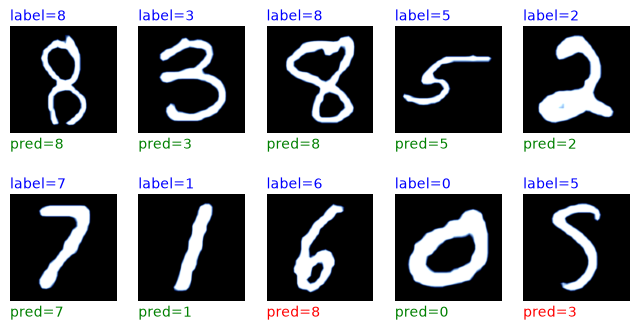

*Random Wrong Predictions from **fine-tune classifier**:*

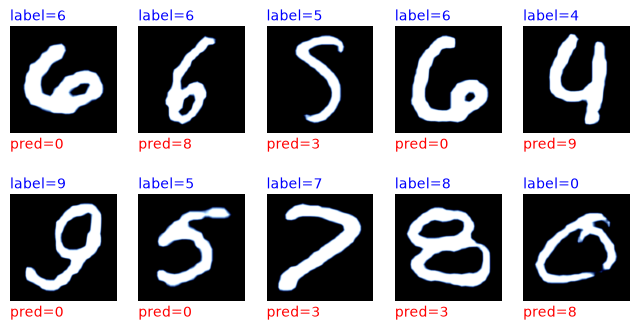

*Training Loss and Validation Accuracy from **fine-tune classifier**:*

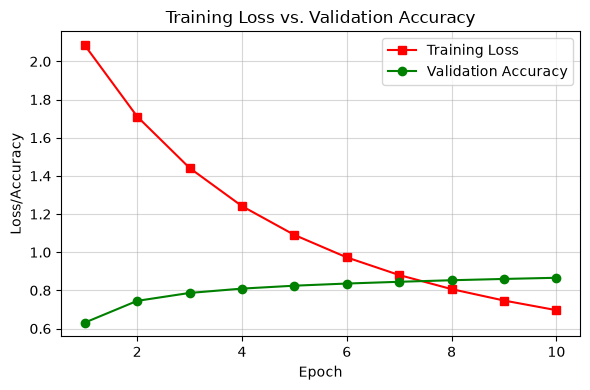

In [36]:
analytics.test_predictions(experiment=experiment_classifier)
analytics.test_wrong_predictions(experiment=experiment_classifier)
analytics.loss_accuracy_plot(experiment=experiment_classifier)

## 26. Scenario 2: Fine-Tuning Classifier plus a few Layers <a id="26-scenario-2-fine-tuning-classifier-plus-a-few-layers"></a>

The final layer of classifier always needs to retrained. Beacause the original output was 1000 (for 1000 image classes) and new output needs to be 10 (for 10 digits), the last layer needs to be redefined and retrained. On top of that, this second scenario gives an option to train a few more layers above the classifier layer. These are the features blocks. In this scenario you can set a number of these blocks to be fine-tuned.

In the example below, 3 features blocks are fine-tuned. That turns out 2.1 million parameters are to be fine-tuned and the remaining (about 2 million) parameters will not be touched during the training.

In [37]:
experiment_classifier_plus = "fine-tune classifier plus"

weights = FinetuningWeights()
data = FinetuningDataModule(root="./data/finetune", weights=weights)
backbone_classifier_plus = FinetuningModule(
    weights=weights, num_layers_to_tune=3
)

trainer_classifier_plus = FinetuningTrainer(
    module=backbone_classifier_plus,
    data=data,
    experiment=experiment_classifier_plus,
    analytics=analytics,
    epochs=10,
)
classifier_plus_finetuned_model = trainer_classifier_plus.fit()

*`FinetuningWeights` is initialized. Metrics:*

metric,value
name,IMAGENET1K_V2
url,https://download.pytorch.org/models/mobilenet_v3_large-5c1a4163.pth
num categories,1000
mean,"[0.485, 0.456, 0.406]"
std,"[0.229, 0.224, 0.225]"
image size,[224]


*`FinetuningDataModule` is initialized. Metrics:*

metric,value
root,./data/finetune
batch_size,256
train_val_split,"(0.8, 0.2)"
train dataset samples,"192,000"
val dataset samples,"48,000"
test dataset samples,"40,000"


*`FinetuningModule` is initialized. Metrics:*

metric,value
model name,mobilenet_v3_large
num feature extractor blocks,17
num classifier layers,4
original model - total parameters,"5,483,032"
original model - num feature parameters,"2,971,952"
original model - num classifier parameters,"2,511,080"
fine-tune model - total parameters,"4,214,842"
fine-tune model - num feature parameters,"2,971,952"
fine-tune model - num classifier parameters,"1,242,890"
fine-tune model - num parameters to tune,"2,196,234"


... (30 outputs left out)

testing:   0%|          | 0/157 [00:00<?, ?batches/s]

Final: testing accuracy = 92.25%


*`FinetuningTrainier` fit() is completed. Metrics:*

metric,value
device,mps
epoch0: training loss,1.998384
epoch 0: validation accuracy,0.607833
epoch1: training loss,1.239540
epoch 1: validation accuracy,0.736229
epoch2: training loss,0.761384
epoch 2: validation accuracy,0.775854
epoch3: training loss,0.530866
epoch 3: validation accuracy,0.870333
epoch4: training loss,0.407027


*Random Predictions from **fine-tune classifier plus**:*

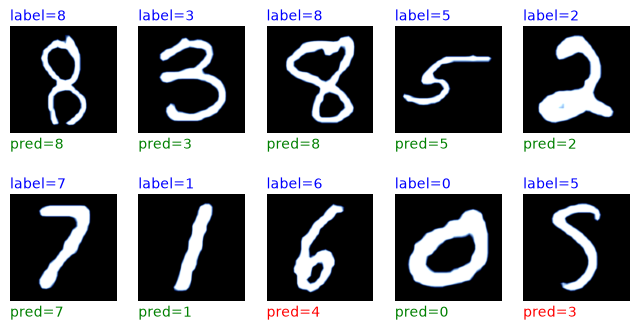

*Random Wrong Predictions from **fine-tune classifier plus**:*

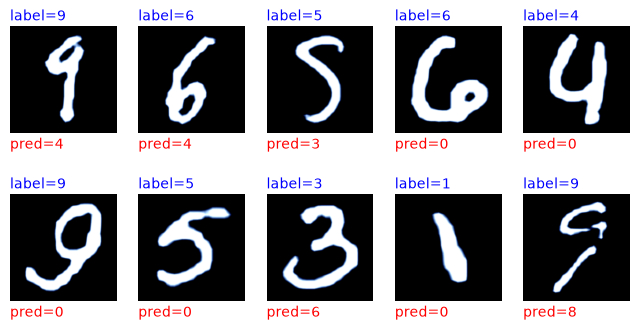

*Training Loss and Validation Accuracy from **fine-tune classifier plus**:*

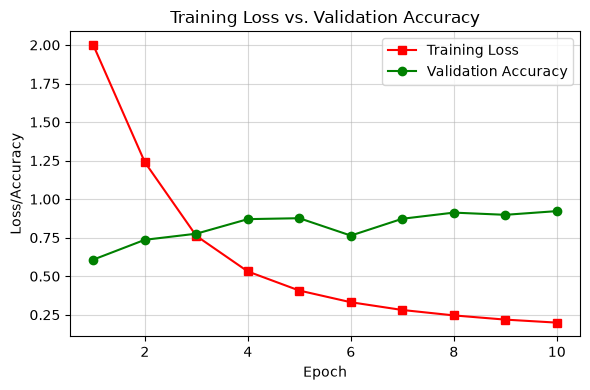

In [38]:
analytics.test_predictions(experiment=experiment_classifier_plus)
analytics.test_wrong_predictions(experiment=experiment_classifier_plus)
analytics.loss_accuracy_plot(experiment=experiment_classifier_plus)

## 27. Scenario 3: Fine-Tuning the Entire Model <a id="27-scenario-3-fine-tuning-the-entire-model"></a>

In this case, the entire model will be fine-tuned. We will start the 4.2 million of the original parameters (except the classifier layer will be new). Once the training is completed, all these parameters will have been tuned.

In [39]:
experiment_full = "fine-tune full model"

weights = FinetuningWeights()
data = FinetuningDataModule(root="./data/finetune", weights=weights)
backbone_full = FinetuningModule(weights=weights, num_layers_to_tune=-1)

trainer_full_model = FinetuningTrainer(
    module=backbone_full,
    data=data,
    experiment=experiment_full,
    analytics=analytics,
    epochs=10,
)
full_finetuned_model = trainer_full_model.fit()

*`FinetuningWeights` is initialized. Metrics:*

metric,value
name,IMAGENET1K_V2
url,https://download.pytorch.org/models/mobilenet_v3_large-5c1a4163.pth
num categories,1000
mean,"[0.485, 0.456, 0.406]"
std,"[0.229, 0.224, 0.225]"
image size,[224]


*`FinetuningDataModule` is initialized. Metrics:*

metric,value
root,./data/finetune
batch_size,256
train_val_split,"(0.8, 0.2)"
train dataset samples,"192,000"
val dataset samples,"48,000"
test dataset samples,"40,000"


*`FinetuningModule` is initialized. Metrics:*

metric,value
model name,mobilenet_v3_large
num feature extractor blocks,17
num classifier layers,4
original model - total parameters,"5,483,032"
original model - num feature parameters,"2,971,952"
original model - num classifier parameters,"2,511,080"
fine-tune model - total parameters,"4,214,842"
fine-tune model - num feature parameters,"2,971,952"
fine-tune model - num classifier parameters,"1,242,890"
fine-tune model - num parameters to tune,"4,214,842"


... (30 outputs left out)

testing:   0%|          | 0/157 [00:00<?, ?batches/s]

Final: testing accuracy = 98.39%


*`FinetuningTrainier` fit() is completed. Metrics:*

metric,value
device,mps
epoch0: training loss,1.758473
epoch 0: validation accuracy,0.727771
epoch1: training loss,0.609454
epoch 1: validation accuracy,0.941021
epoch2: training loss,0.241337
epoch 2: validation accuracy,0.965583
epoch3: training loss,0.144667
epoch 3: validation accuracy,0.965063
epoch4: training loss,0.106288


*Random Predictions from **fine-tune full model**:*

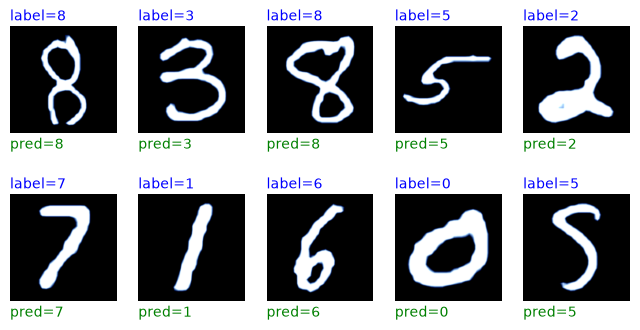

*Random Wrong Predictions from **fine-tune full model**:*

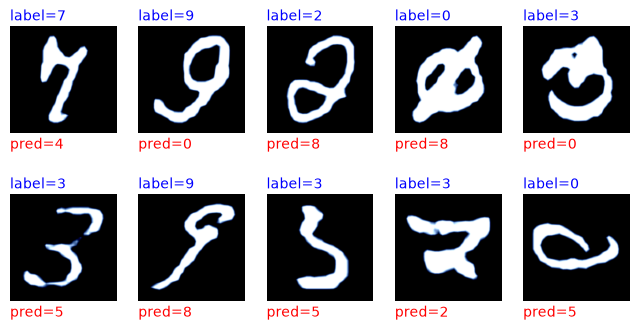

*Training Loss and Validation Accuracy from **fine-tune full model**:*

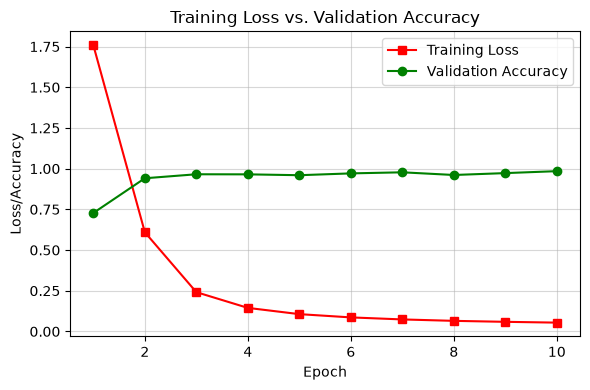

In [40]:
analytics.test_predictions(experiment=experiment_full)
analytics.test_wrong_predictions(experiment=experiment_full)
analytics.loss_accuracy_plot(experiment=experiment_full)

# IX. Conclusion <a id="ix-conclusion"></a>




## 28. Compare Approaches <a id="28-compare-approaches"></a>



*Accuracy Comparison between experiments: **['fine-tune classifier', 'fine-tune classifier plus', 'fine-tune full model']**:*

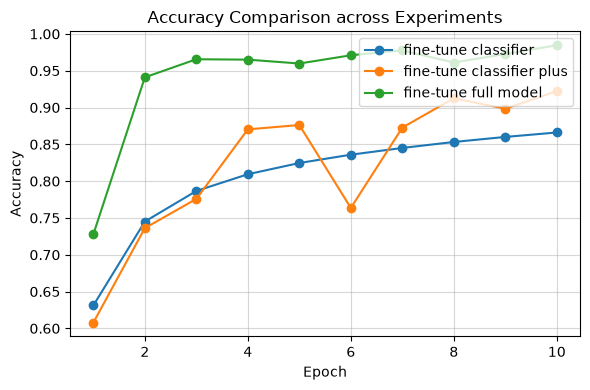

In [41]:
analytics.accuracy_compare_plot()